# Bank of the Future: Python analysis

The SQL in `sql/analysis/` measures *what* happened. This notebook goes a step further with Python:

1. **Explore**: how unequal customer balances are, and how long check reviews really take
2. **Test**: whether the gaps the SQL found are real or just chance
3. **Predict**: which active customers are about to go dormant

It reads the PostgreSQL `bank` database that `python build.py` creates. To run it yourself, open it in VS Code or run `jupyter notebook` with the project's `.venv` activated.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.lines import Line2D
from matplotlib.ticker import PercentFormatter
from psycopg.types.numeric import FloatLoader

from build import connect

db = connect('bank')
db.adapters.register_loader('numeric', FloatLoader)   # load NUMERIC money as floats so pandas can do math on it


def query(sql):
    rows = db.execute(sql)
    return pd.DataFrame(rows.fetchall(), columns=[column.name for column in rows.description])


# Quiet axes and gridlines so the data stands out
SURFACE, INK, MUTED, BLUE, ORANGE = '#fcfcfb', '#0b0b0b', '#898781', '#2a78d6', '#eb6834'
plt.rcParams.update({
    'figure.facecolor': SURFACE, 'axes.facecolor': SURFACE, 'savefig.facecolor': SURFACE, 'figure.dpi': 110,
    'font.family': 'sans-serif', 'font.sans-serif': ['Segoe UI', 'DejaVu Sans'],
    'axes.titlesize': 13, 'axes.titleweight': 'semibold', 'axes.titlelocation': 'left', 'axes.titlecolor': INK,
    'axes.labelcolor': '#52514e', 'axes.edgecolor': '#c3c2b7', 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'axes.axisbelow': True, 'grid.color': '#e1e0d9', 'grid.linewidth': 1,
    'xtick.color': MUTED, 'ytick.color': MUTED, 'lines.linewidth': 2,
})

## 1. Explore

### How unequal are balances?

SQL query 03 found that the top 10% of customers hold 40% of the money. A **Lorenz curve** shows the whole distribution in one line: customers sorted from smallest balance to largest, against the share of money they hold together. The **Gini coefficient** sums it up in one number: 0 means everyone holds the same amount, and 1 means one customer holds everything.

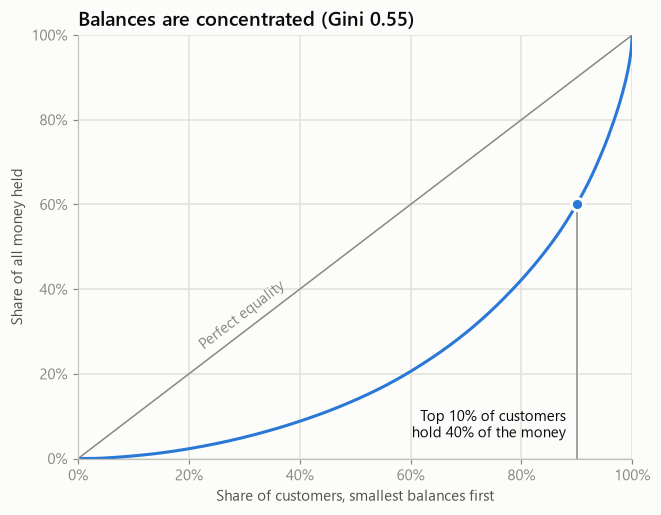

Gini coefficient: 0.547   Top 10% hold 39.9%   Median balance: $7,322


In [2]:
customers = query('SELECT customer_id, balance, status, has_savings FROM v_customers')
balances = np.sort(customers['balance'].to_numpy())
n = len(balances)
share_of_customers = np.r_[0, np.arange(1, n + 1) / n]
share_of_money = np.r_[0, balances.cumsum() / balances.sum()]
gini = 2 * np.sum(np.arange(1, n + 1) * balances) / (n * balances.sum()) - (n + 1) / n
top_10_share = 1 - share_of_money[int(n * 0.9)]

fig, ax = plt.subplots(figsize=(6.5, 5))
ax.plot(share_of_customers, share_of_money, color=BLUE)
ax.plot([0, 1], [0, 1], color=MUTED, linewidth=1)
ax.text(0.3, 0.33, 'Perfect equality', color=MUTED, rotation=45, transform_rotates_text=True,
        rotation_mode='anchor', ha='center')
ax.plot([0.9, 0.9], [0, 1 - top_10_share], color=MUTED, linewidth=1)
ax.plot(0.9, 1 - top_10_share, 'o', color=BLUE, markersize=8, markeredgecolor=SURFACE, markeredgewidth=2)
ax.text(0.88, 0.05, f'Top 10% of customers\nhold {top_10_share:.0%} of the money', color=INK, ha='right')
ax.set(title=f'Balances are concentrated (Gini {gini:.2f})',
       xlabel='Share of customers, smallest balances first', ylabel='Share of all money held', xlim=(0, 1), ylim=(0, 1))
ax.xaxis.set_major_formatter(PercentFormatter(1))
ax.yaxis.set_major_formatter(PercentFormatter(1))
plt.show()
print(f'Gini coefficient: {gini:.3f}   Top 10% hold {top_10_share:.1%}   Median balance: ${np.median(balances):,.0f}')

The curve bows far below the equality line. A Gini of 0.55 is high: for comparison, US household income is around 0.49. A few large customers matter a lot, because losing one of them costs as much money as losing dozens of typical ones.

### How long do check reviews take?

Reviewers only work weekdays from 9:00 to 17:00. Each line below shows the spread of waits for checks sent on that day: the dot is the median, and the bar runs from the 10th to the 90th percentile.

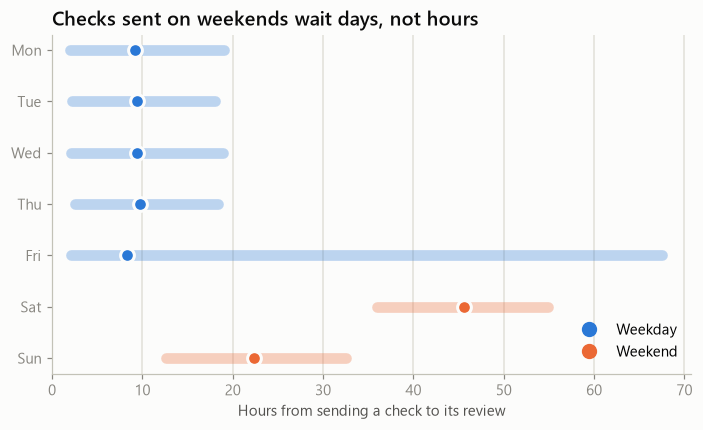

,p10_hours,median_hours,p90_hours
day_sent,,,
Mon,2.0,9.2,19.0
Tue,2.2,9.4,18.0
Wed,2.1,9.4,18.9
Thu,2.5,9.7,18.4
Fri,2.1,8.3,67.5
Sat,36.0,45.6,54.9
Sun,12.6,22.4,32.5


In [3]:
deposits = query("""
    SELECT created_at, amount, status, reviewed_by, review_hours
    FROM v_transactions
    WHERE type = 'Deposit' AND status <> 'Pending'""")
deposits['day_sent'] = deposits['created_at'].dt.day_name().str[:3]
deposits['weekend'] = deposits['created_at'].dt.day_of_week >= 5

days = ['Mon', 'Tue', 'Wed', 'Thu', 'Fri', 'Sat', 'Sun']
spread = deposits.groupby('day_sent')['review_hours'].quantile([0.1, 0.5, 0.9]).unstack().loc[days]
spread.columns = ['p10_hours', 'median_hours', 'p90_hours']

fig, ax = plt.subplots(figsize=(7.5, 4))
for i, (day, row) in enumerate(spread.iterrows()):
    color = ORANGE if day in ('Sat', 'Sun') else BLUE
    ax.plot([row['p10_hours'], row['p90_hours']], [i, i], color=color, alpha=0.3, linewidth=7, solid_capstyle='round')
    ax.plot(row['median_hours'], i, 'o', color=color, markersize=9, markeredgecolor=SURFACE, markeredgewidth=2)
ax.set_yticks(range(len(days)), days)
ax.invert_yaxis()
ax.grid(axis='y', visible=False)
ax.set(title='Checks sent on weekends wait days, not hours',
       xlabel='Hours from sending a check to its review', xlim=(0, None))
ax.legend(handles=[Line2D([], [], marker='o', linestyle='', color=c, markersize=9, label=l)
                   for c, l in [(BLUE, 'Weekday'), (ORANGE, 'Weekend')]], frameon=False, loc='lower right')
plt.show()
spread.round(1)

Monday to Thursday checks are reviewed within a working day. Saturday's median wait is about 46 hours, because nothing moves until Monday morning. Friday's spread is the widest: a check sent Friday morning clears that afternoon, but one sent Friday evening waits all weekend.

## 2. Test: real effects, or chance?

The SQL found two gaps: weekend checks wait longer, and some reviewers deny more checks than others. Any two groups differ a little by luck. A statistical test asks: *if there were really no difference, how likely would a gap this big be?* That probability is the **p-value**, and below 0.05 is the usual bar for calling a difference real.

### Do weekend checks really wait longer?

Waiting times are skewed: most are short and a few are very long. So this uses the **Mann-Whitney U test**, which compares the ranks of the waits instead of their averages and doesn't assume a bell curve.

In [4]:
from scipy import stats


def p_value(p):
    return 'p < 0.001' if p < 0.001 else f'p = {p:.3f}'


weekday = deposits.loc[~deposits['weekend'], 'review_hours']
weekend = deposits.loc[deposits['weekend'], 'review_hours']
u, p = stats.mannwhitneyu(weekend, weekday, alternative='greater')
print(f'Median wait: weekday {weekday.median():.1f} hours, weekend {weekend.median():.1f} hours')
print(f'Mann-Whitney U = {u:,.0f}, {p_value(p)}')
print(f'A random weekend check waits longer than a random weekday check {u / (len(weekend) * len(weekday)):.0%} of the time')

Median wait: weekday 9.2 hours, weekend 34.0 hours
Mann-Whitney U = 246,131,034, p < 0.001
A random weekend check waits longer than a random weekday check 88% of the time


**Yes, beyond doubt** (p < 0.001). The median weekend check waits 34 hours, against 9 on a weekday, and a random weekend check waits longer than a random weekday check 88% of the time. **Recommendation:** a short Saturday review shift would remove the longest waits.

### Do some reviewers really deny more checks?

A **chi-square test** checks whether a check's outcome (approved or denied) depends on who reviews it. Big checks are denied more often, so the test is run separately for checks under \$2,500 and checks of \$2,500 or more. That way, a reviewer who happened to get bigger checks can't skew the result.

In [5]:
deposits['denied'] = deposits['status'] == 'Denied'
deposits['large'] = deposits['amount'] >= 2500
for large, group in deposits.groupby('large'):
    chi2, p, dof, _ = stats.chi2_contingency(pd.crosstab(group['reviewed_by'], group['denied']))
    label = 'Checks of $2,500 or more' if large else 'Checks under $2,500'
    print(f'{label}: chi-square = {chi2:.1f} ({dof} degrees of freedom), {p_value(p)}')

Checks under $2,500: chi-square = 115.1 (5 degrees of freedom), p < 0.001
Checks of $2,500 or more: chi-square = 96.4 (5 degrees of freedom), p < 0.001


The chart shows each reviewer's denial rate with a **95% confidence interval**: the range their true rate most likely falls in, given how many checks they've reviewed. Where a reviewer's interval doesn't reach the team rate, the difference is unlikely to be chance.

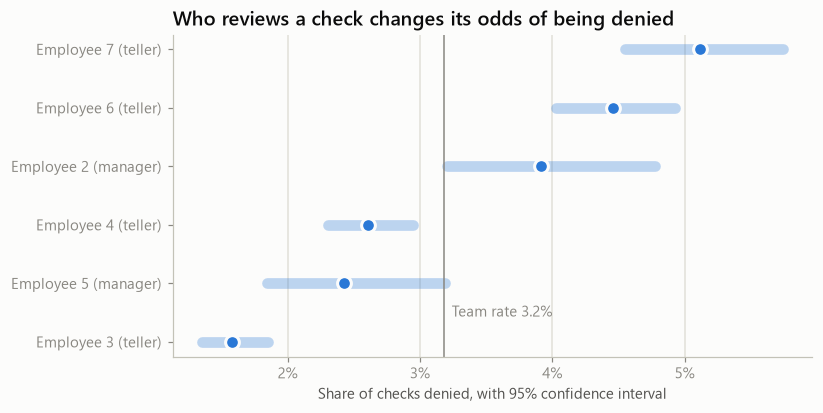

,reviews,denied,denial_rate,ci_low,ci_high,large_check_share
reviewed_by,,,,,,
3,9539,151,0.016,0.014,0.019,0.162
5,2058,50,0.024,0.018,0.032,0.155
4,9443,246,0.026,0.023,0.029,0.159
2,2350,92,0.039,0.032,0.048,0.156
6,8099,361,0.045,0.040,0.049,0.156
7,5241,268,0.051,0.045,0.057,0.166


In [6]:
tiers = query('SELECT id, tier FROM employees').set_index('id')['tier']
rates = deposits.groupby('reviewed_by').agg(reviews=('denied', 'size'), denied=('denied', 'sum'),
                                            large_check_share=('large', 'mean'))
rates['denial_rate'] = rates['denied'] / rates['reviews']
intervals = [stats.binomtest(int(d), int(n)).proportion_ci(method='wilson') for d, n in zip(rates['denied'], rates['reviews'])]
rates['ci_low'] = [i.low for i in intervals]
rates['ci_high'] = [i.high for i in intervals]
rates = rates.sort_values('denial_rate')
team_rate = rates['denied'].sum() / rates['reviews'].sum()

fig, ax = plt.subplots(figsize=(7.5, 3.8))
for i, (employee, row) in enumerate(rates.iterrows()):
    ax.plot([row['ci_low'], row['ci_high']], [i, i], color=BLUE, alpha=0.3, linewidth=7, solid_capstyle='round')
    ax.plot(row['denial_rate'], i, 'o', color=BLUE, markersize=9, markeredgecolor=SURFACE, markeredgewidth=2)
ax.axvline(team_rate, color=MUTED, linewidth=1)
ax.text(team_rate, 0.5, f'  Team rate {team_rate:.1%}', color=MUTED, va='center')  # empty gap beside the line
ax.set_yticks(range(len(rates)), [f'Employee {e} ({"teller" if tiers[e] == 1 else "manager"})' for e in rates.index])
ax.grid(axis='y', visible=False)
ax.xaxis.set_major_formatter(PercentFormatter(1, decimals=0))
ax.set(title='Who reviews a check changes its odds of being denied', xlabel='Share of checks denied, with 95% confidence interval')
plt.show()
rates[['reviews', 'denied', 'denial_rate', 'ci_low', 'ci_high', 'large_check_share']].round(3)

**Yes.** For both check sizes, p < 0.001: whether a check is denied depends on who reviews it. Employee 3 denies 1.6% of checks (interval 1.4% to 1.9%) and employee 7 denies 5.1% (4.5% to 5.7%), more than three times as often, and their intervals don't come close. Every reviewer gets about the same share of large checks (15-17%), so the gap isn't about which checks they see. **Recommendation:** written denial criteria, plus a regular session where reviewers judge the same sample of checks and compare their decisions.

## 3. Predict: who is about to go dormant?

SQL query 05 found \$2.4M sitting with dormant customers. Reaching people *before* they leave is cheaper than winning them back, so this section asks: **looking at the bank on 1 July 2026, can we tell which active customers will stop moving money over the next three months?**

The features are built in SQL from data *before* the snapshot date only, so the model never sees the future it's predicting.

In [7]:
FEATURES_SQL = '''
WITH own_moves AS (   -- money the customer moved themselves
    SELECT a.customer_id, t.created_at, t.type, t.status, t.amount
    FROM transactions t
    JOIN accounts a ON a.account_number = t.account_number
    WHERE t.type IN ('Deposit', 'Withdrawal', 'Transfer Out')
),
history AS (
    SELECT customer_id,
           MAX(created_at) AS last_active_at,
           COUNT(*) FILTER (WHERE created_at >= timestamp '{snapshot}' - interval '30 days') AS moves_last_30_days,
           COUNT(*) FILTER (WHERE created_at <  timestamp '{snapshot}' - interval '30 days'
                              AND created_at >= timestamp '{snapshot}' - interval '90 days') AS moves_prior_60_days,
           COUNT(*) FILTER (WHERE type = 'Deposit' AND status = 'Denied') AS denied_checks,
           AVG(amount) FILTER (WHERE type = 'Deposit') AS avg_check
    FROM own_moves
    WHERE created_at < timestamp '{snapshot}'
    GROUP BY customer_id
),
holdings AS (   -- balances at the end of the month before the snapshot
    SELECT customer_id, SUM(end_balance) AS balance, bool_or(account_type = 'Savings') AS has_savings
    FROM v_monthly_balances
    WHERE month = date_trunc('month', timestamp '{snapshot}' - interval '1 day')
    GROUP BY customer_id
)
SELECT c.id AS customer_id,
       EXTRACT(DAY FROM timestamp '{snapshot}' - c.created_at)::int AS tenure_days,
       EXTRACT(EPOCH FROM timestamp '{snapshot}' - h.last_active_at) / 86400 AS days_since_active,
       h.moves_last_30_days, h.moves_prior_60_days, h.denied_checks, h.avg_check,
       b.balance, b.has_savings,
       NOT EXISTS (SELECT 1 FROM own_moves m WHERE m.customer_id = c.id AND m.created_at >= timestamp '{snapshot}') AS went_dormant
FROM customers c
JOIN history h ON h.customer_id = c.id
JOIN holdings b ON b.customer_id = c.id
WHERE c.created_at < timestamp '{snapshot}' - interval '90 days'     -- customers with at least 90 days of history
  AND h.last_active_at >= timestamp '{snapshot}' - interval '90 days' -- who are still active at the snapshot
'''
FEATURES = {
    'days_since_active': 'Days since last activity',
    'moves_last_30_days': 'Transactions in the last 30 days',
    'moves_prior_60_days': 'Transactions 30-90 days before',
    'tenure_days': 'Days as a customer',
    'denied_checks': 'Denied checks',
    'avg_check': 'Average check size',
    'balance': 'Balance',
    'has_savings': 'Has a savings account',
}

snapshot = query(FEATURES_SQL.format(snapshot='2026-07-01'))
print(f"{len(snapshot):,} active customers on 1 July 2026; {snapshot['went_dormant'].mean():.1%} went dormant by the end of September")

1,108 active customers on 1 July 2026; 4.4% went dormant by the end of September


The model is a **logistic regression**: it weighs each feature to estimate a probability of going dormant. It's trained on 70% of customers and scored on the other 30%, which it never saw.

Accuracy is measured with **ROC AUC**: the chance that the model ranks a customer who left above one who stayed. 0.5 is a coin flip and 1.0 is perfect. The baseline is the simplest possible rule: rank customers by how long it's been since they last moved money.

To see which features the model really relies on, each one is scrambled in turn on the test customers (**permutation importance**). If the AUC drops, the feature mattered; if it doesn't, the model was getting nothing from it.

Model ROC AUC: 0.934
"Days since last activity" alone: 0.935


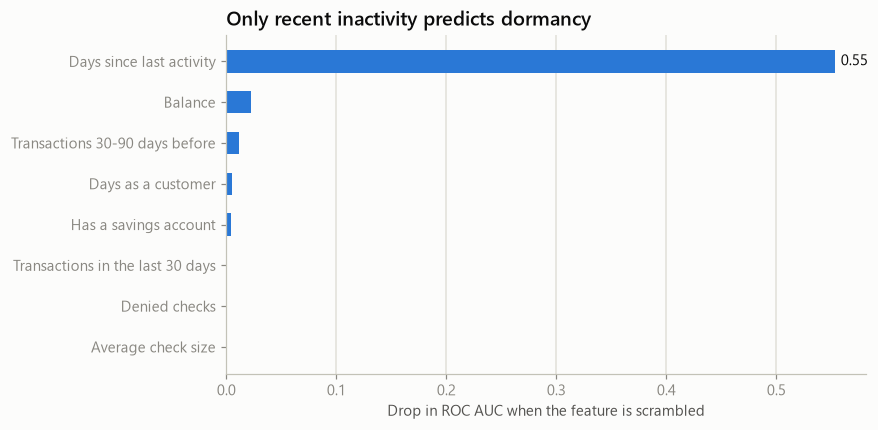

,auc_drop
Average check size,-0.008
Denied checks,-0.000
Transactions in the last 30 days,0.000
Has a savings account,0.004
Days as a customer,0.005
Transactions 30-90 days before,0.011
Balance,0.022
Days since last activity,0.554


In [8]:
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

X = snapshot[list(FEATURES)].astype(float)
y = snapshot['went_dormant']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, stratify=y, random_state=42)

model = make_pipeline(StandardScaler(), LogisticRegression())
model.fit(X_train, y_train)
model_auc = roc_auc_score(y_test, model.predict_proba(X_test)[:, 1])
rule_auc = roc_auc_score(y_test, X_test['days_since_active'])
print(f'Model ROC AUC: {model_auc:.3f}')
print(f'"Days since last activity" alone: {rule_auc:.3f}')

importance = permutation_importance(model, X_test, y_test, scoring='roc_auc', n_repeats=30, random_state=42)
auc_drop = pd.Series(importance.importances_mean, index=[FEATURES[f] for f in FEATURES]).sort_values()
fig, ax = plt.subplots(figsize=(7.5, 4))
ax.barh(auc_drop.index, auc_drop.clip(lower=0), height=0.55, color=BLUE)
ax.text(auc_drop.iloc[-1] + 0.005, len(auc_drop) - 1, f'{auc_drop.iloc[-1]:.2f}', va='center', color=INK)
ax.grid(axis='y', visible=False)
ax.set(title='Only recent inactivity predicts dormancy', xlabel='Drop in ROC AUC when the feature is scrambled')
plt.show()
auc_drop.round(3).to_frame('auc_drop')

**The model works, but it doesn't beat the simple rule:** ROC AUC 0.934, against 0.935 for "days since last activity" on its own. Scrambling that one feature drops the AUC by 0.55, while scrambling any other barely changes it. So balance, savings, denied checks and check size don't tell you who will leave. How long someone has been quiet does. That's a useful answer in itself: the bank doesn't need a model, just a weekly report of customers who have gone quiet. (Only 49 customers went dormant in this window, so small effects from the other features can't be ruled out.)

### Who to call this week

Applying the same features to the end of the data gives a ranked list of active customers who look like they're slipping away, with the money they hold.

In [9]:
today = query(FEATURES_SQL.format(snapshot='2026-10-01'))
today['dormancy_risk'] = model.predict_proba(today[list(FEATURES)].astype(float))[:, 1]
at_risk = today.sort_values('dormancy_risk', ascending=False).head(10)
print(f"{(today['dormancy_risk'] > 0.5).sum()} of {len(today):,} active customers are more likely than not to go dormant, "
      f"holding ${today.loc[today['dormancy_risk'] > 0.5, 'balance'].sum():,.0f}")
at_risk[['customer_id', 'dormancy_risk', 'days_since_active', 'moves_last_30_days', 'balance']].round(2)

53 of 1,390 active customers are more likely than not to go dormant, holding $701,714


,customer_id,dormancy_risk,days_since_active,moves_last_30_days,balance
225,341,1.0,88.07,0,6845.22
855,1096,1.0,88.00,0,13902.62
609,826,1.0,88.26,0,17321.25
398,568,1.0,82.44,0,3133.13
1263,1523,1.0,85.07,0,2857.48
1285,1545,1.0,84.33,0,2520.88
329,481,1.0,81.35,0,23198.98
930,1175,1.0,81.71,0,4779.96
1297,1557,1.0,83.47,0,2302.69
809,1047,1.0,78.88,0,7378.46


53 active customers are more likely than not to go dormant, and together they hold \$702K. None of the top ten have moved money for 11 to 13 weeks. **Recommendation:** contact customers soon after they go quiet, before they cross the 90-day dormancy line, starting with the largest balances.